# ARTI 403 — Image Processing
## Lab 4 — Intensity Transformations and Filtering - Spatial Domain

**College of Computer Science and Information Technology — Department of Computer Engineering**  
**Imam Abdulrahman Bin Faisal University — 2026 / 2027**

| | |
|---|---|
| **Session topic** | Intensity Transformations and Filtering - Spatial Domain |
| **Session No.** | 4 |
| **Duration** | 100 minutes |
| **Student name** | Abdulrahman Saleh Alaamri |
| **Student ID** | 2240002427 |

**Outcome #2:** Write a program that implements fundamental image processing algorithms.

## 1. Procedural steps

### Task 1: Thresholding

Thresholding changes a gray image into a binary image. Pixels above the threshold become white (255) and the other pixels become black (0).

The manual uses `Parrot.png`, but this image is not in my repo, so I used `cameraman.tif`. I also show the results with matplotlib because `cv2.imshow` opens separate windows and does not work well in a notebook.

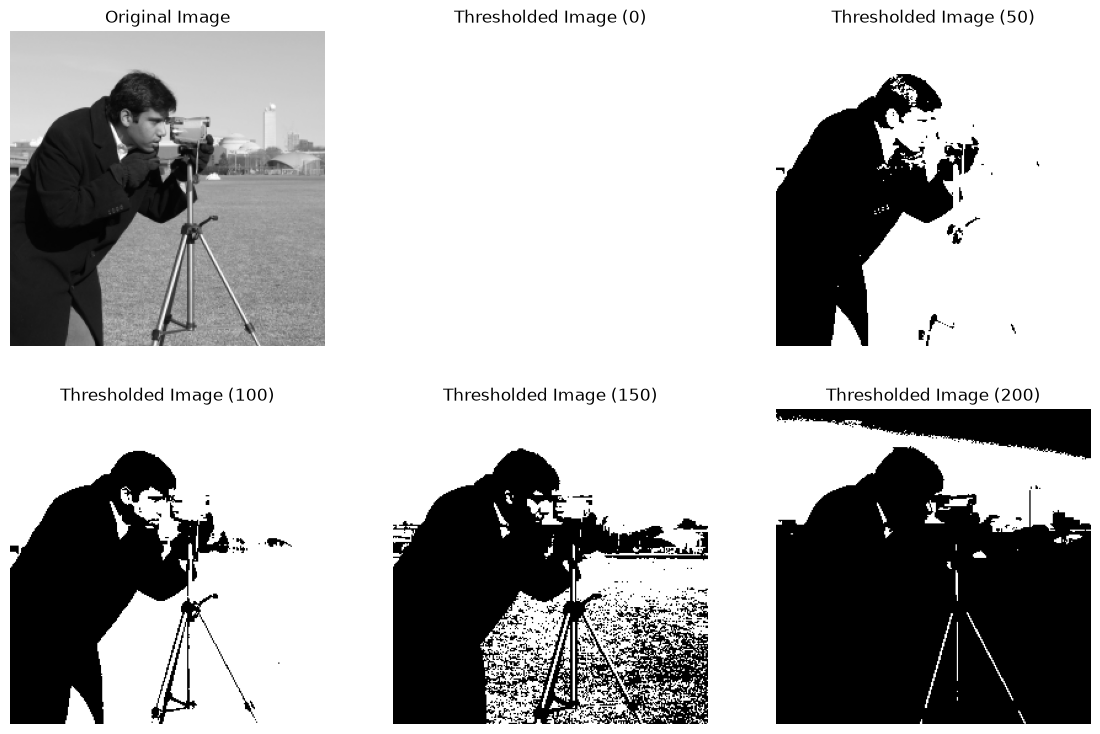

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

img = cv2.imread('../images/cameraman.tif', cv2.IMREAD_GRAYSCALE)

threshold_values = [0, 50, 100, 150, 200]

plt.figure(figsize=(14, 9))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Original Image')
plt.axis('off')

for i, threshold_value in enumerate(threshold_values, 2):
    ret, thresh = cv2.threshold(img, threshold_value, 255, cv2.THRESH_BINARY)
    plt.subplot(2, 3, i)
    plt.imshow(thresh, cmap='gray', vmin=0, vmax=255)
    plt.title(f'Thresholded Image ({threshold_value})')
    plt.axis('off')

plt.show()

**Observation:** With threshold 0 the whole image is white because every pixel is above 0 (the lowest pixel value is 2). When the threshold goes up, more pixels become black. With 100 the man and the camera are clearly separated from the sky. With 200 only the brightest parts are left.

### Task 2: Histogram Processing

#### Step 1: Load the libraries

In [2]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

from skimage import data, img_as_float
from skimage import exposure

#### Step 2: Load the moon image

In [3]:
img = data.moon()
print(img.shape, img.dtype)

(512, 512) uint8


#### Step 3: Contrast stretching

I rescale the intensities so that the values between the 2nd and the 98th percentiles fill the full range.

In [4]:
p2, p98 = np.percentile(img, (2, 98))
img_rescale = exposure.rescale_intensity(img, in_range=(p2, p98))

print("2nd percentile  :", p2)
print("98th percentile :", p98)

2nd percentile  : 78.0
98th percentile : 129.0


#### Step 4: Display the images with their histograms

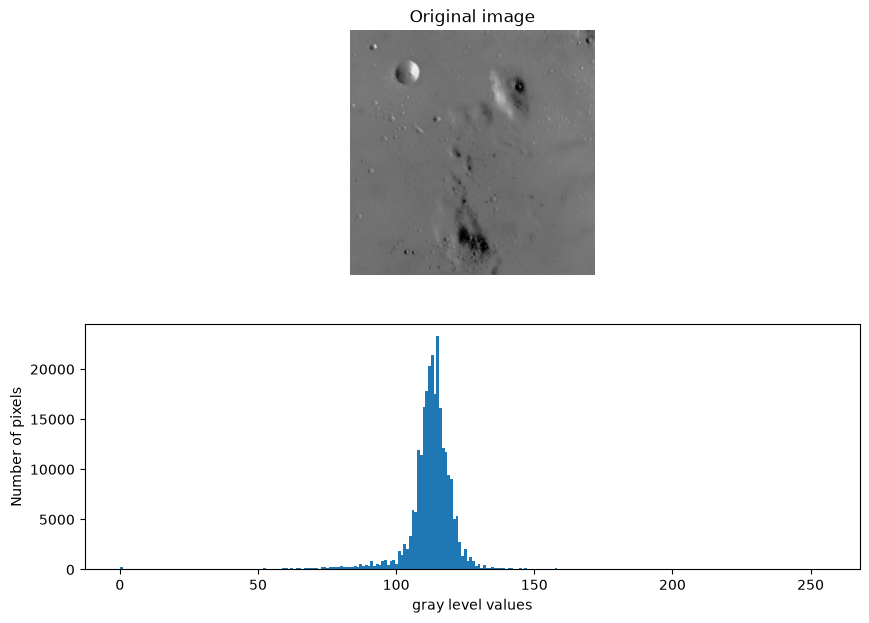

In [5]:
fig = plt.figure(figsize=(10, 7))
fig.add_subplot(2, 1, 1)
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.title('Original image')
fig.add_subplot(2, 1, 2)
plt.hist(img.flat, bins=256, range=(0, 255))
plt.xlabel('gray level values')
plt.ylabel('Number of pixels')
plt.show()

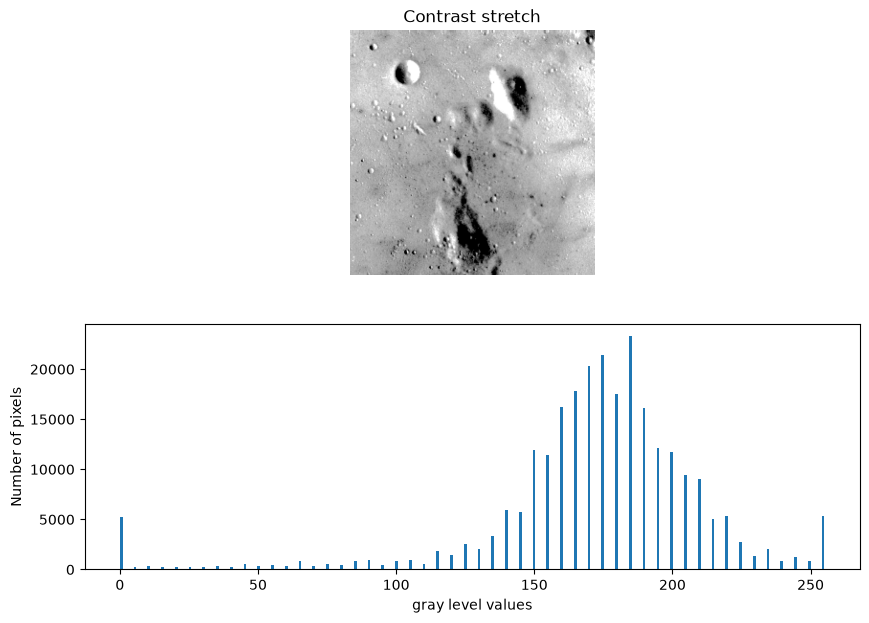

In [6]:
fig = plt.figure(figsize=(10, 7))
fig.add_subplot(2, 1, 1)
plt.imshow(img_rescale, cmap='gray')
plt.axis('off')
plt.title('Contrast stretch')
fig.add_subplot(2, 1, 2)
plt.hist(img_rescale.flat, bins=256, range=(0, 255))
plt.xlabel('gray level values')
plt.ylabel('Number of pixels')
plt.show()

**Observation:** The original histogram is a narrow peak around gray level 110 (the 2nd and 98th percentiles are 78 and 129), so the moon looks flat and gray. After the stretch the histogram uses almost the whole range from 0 to 255 and the craters are easier to see. The pixels outside the two percentiles go to 0 or 255.

## 2. Assessment

I use the same function to show an image with its histogram in the three tasks.

In [7]:
def show_hist(image, title):
    fig = plt.figure(figsize=(10, 7))
    fig.add_subplot(2, 1, 1)
    plt.imshow(image, cmap='gray')
    plt.axis('off')
    plt.title(title)
    fig.add_subplot(2, 1, 2)
    plt.hist(image.flat, bins=256, range=(0, 255))
    plt.xlabel('gray level values')
    plt.ylabel('Number of pixels')
    plt.show()

### Task 1: Rescale the intensities between the 3rd and 80th percentiles

3rd percentile  : 87.0
80th percentile : 118.0
pixels at 0   : 3.1 %
pixels at 255 : 21.0 %


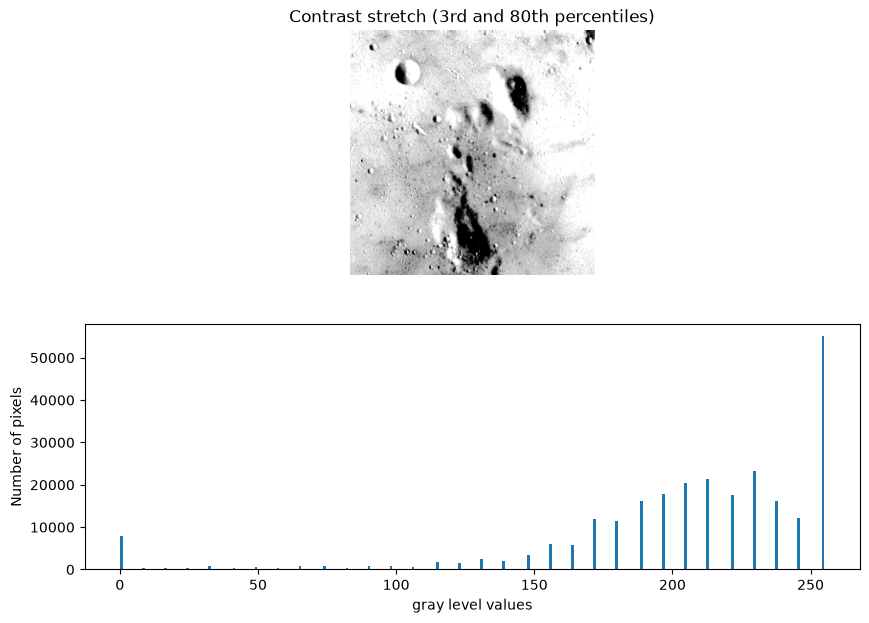

In [8]:
img = data.moon()

p3, p80 = np.percentile(img, (3, 80))
img_rescale_3_80 = exposure.rescale_intensity(img, in_range=(p3, p80))

print("3rd percentile  :", p3)
print("80th percentile :", p80)
print("pixels at 0   :", f"{100 * (img_rescale_3_80 == 0).mean():.1f} %")
print("pixels at 255 :", f"{100 * (img_rescale_3_80 == 255).mean():.1f} %")

show_hist(img_rescale_3_80, 'Contrast stretch (3rd and 80th percentiles)')

**Observation:** This stretch is stronger than the 2 - 98 one. All the pixels above the 80th percentile (20 % of the image) become white, so the bright areas lose their details, but the dark and middle areas get more contrast. The histogram has a big spike at 255 for this reason.

### Task 2: Histogram equalization

`exposure.equalize_hist` flattens the histogram. It returns values between 0 and 1, so I convert the result back to 8 bits before plotting.

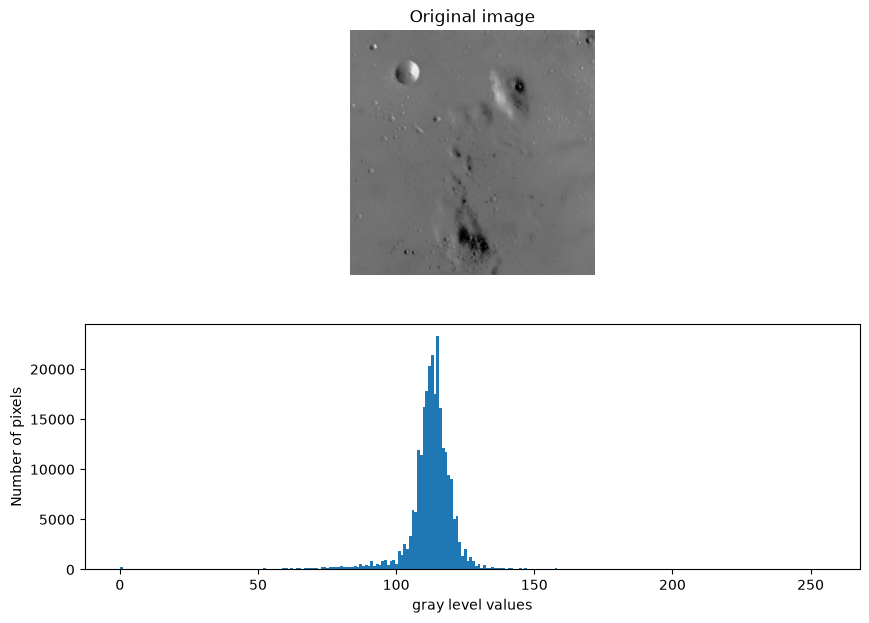

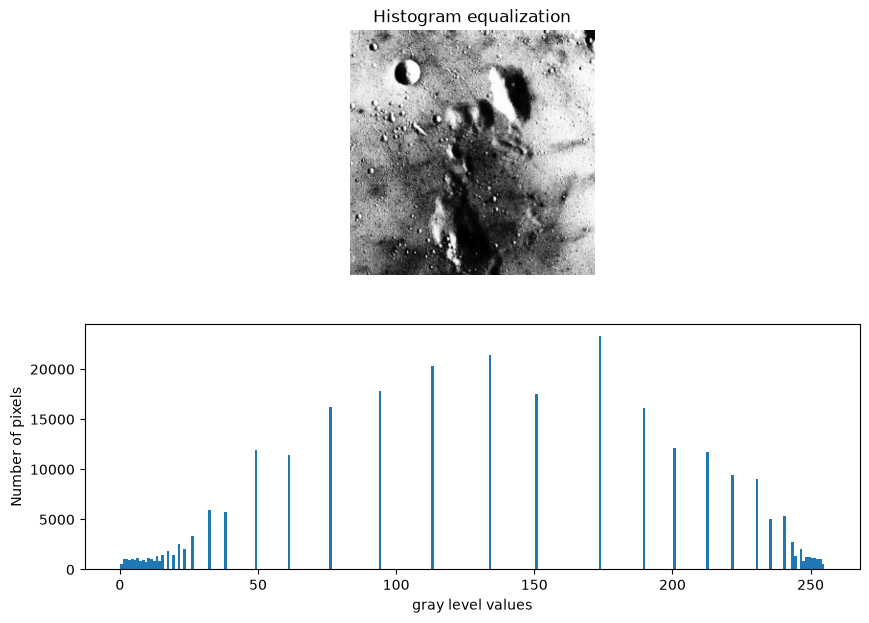

In [9]:
from skimage import img_as_ubyte

img_eq = exposure.equalize_hist(img)
img_eq = img_as_ubyte(img_eq)

show_hist(img, 'Original image')
show_hist(img_eq, 'Histogram equalization')

**Observation:** After equalization the gray levels are spread over the whole range and the histogram is much flatter than the original. The craters and the dark areas show more details. The histogram is not perfectly flat, because the gray levels are integers and a level cannot be split.

### Task 3: Histogram matching

I use the Chelsea image as the source and the rocket image as the reference. The matched image keeps the content of Chelsea but its colors follow the histogram of the rocket image.

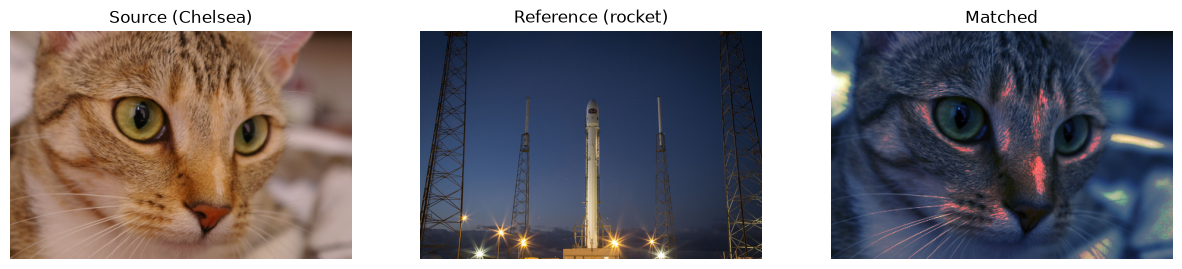

In [10]:
reference = data.rocket()
image = data.chelsea()

matched = exposure.match_histograms(image, reference, channel_axis=-1)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(image)
ax[0].set_title('Source (Chelsea)')
ax[0].axis('off')

ax[1].imshow(reference)
ax[1].set_title('Reference (rocket)')
ax[1].axis('off')

ax[2].imshow(matched)
ax[2].set_title('Matched')
ax[2].axis('off')

plt.show()

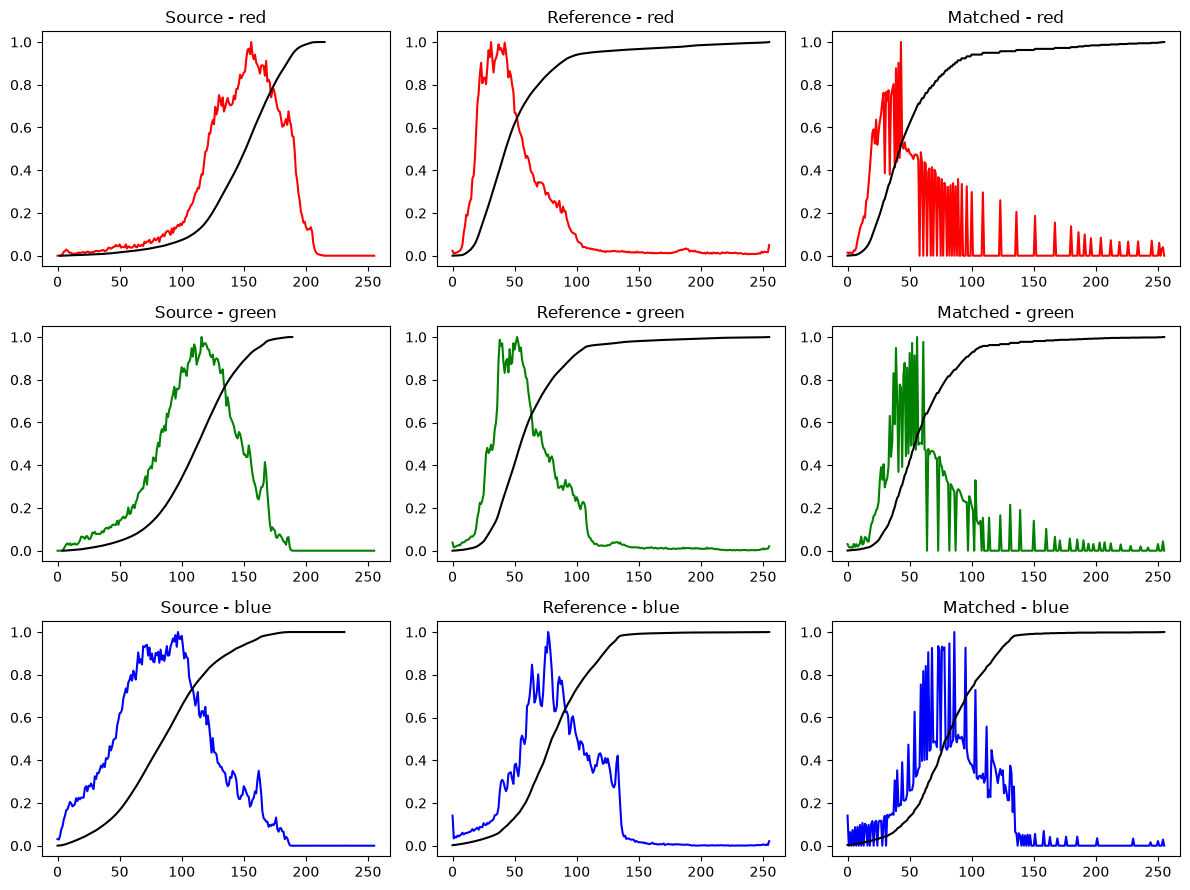

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
channels = ['red', 'green', 'blue']
names = ['Source', 'Reference', 'Matched']

for i, c in enumerate(channels):
    for j, im in enumerate([image, reference, matched]):
        hist, bins = exposure.histogram(im[..., i], source_range='dtype')
        cdf, cdf_bins = exposure.cumulative_distribution(im[..., i])
        axes[i, j].plot(bins, hist / hist.max(), color=c)
        axes[i, j].plot(cdf_bins, cdf, color='black')
        axes[i, j].set_title(f'{names[j]} - {c}')

plt.tight_layout()
plt.show()

**Observation:** The color histograms (colored lines) and the cumulative distributions (black lines) of the matched image are very close to the ones of the reference and not to the source. This shows that histogram matching moves the intensity distribution of each channel to the distribution of the reference image.

## 3. Saving the images used and the results

In [12]:
os.makedirs('output', exist_ok=True)

cv2.imwrite('output/moon.png', img)
cv2.imwrite('output/rocket.png', cv2.cvtColor(reference, cv2.COLOR_RGB2BGR))
cv2.imwrite('output/chelsea.png', cv2.cvtColor(image, cv2.COLOR_RGB2BGR))

cv2.imwrite('output/task1_rescale_3_80.png', img_rescale_3_80)
cv2.imwrite('output/task2_equalized.png', img_eq)
cv2.imwrite('output/task3_matched.png', cv2.cvtColor(matched, cv2.COLOR_RGB2BGR))

print(sorted(os.listdir('output')))

['chelsea.png', 'moon.png', 'rocket.png', 'task1_rescale_3_80.png', 'task2_equalized.png', 'task3_matched.png']


## 4. Conclusion

- Thresholding makes a binary image. The result depends a lot on the threshold value.
- Contrast stretching with percentiles makes the image use the full range of gray levels. A smaller upper percentile gives more contrast but loses the bright details.
- Histogram equalization flattens the histogram and improves the contrast without choosing any parameter.
- Histogram matching changes the histogram of an image to look like the histogram of a reference image.